Celda 1: Importar librerías y fijar semillas (Reproducibilidad)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, auc, average_precision_score, confusion_matrix

import tensorflow as tf
import keras
from keras import layers, models

# Fijamos las semillas
np.random.seed(42)
tf.random.set_seed(42)

print("Librerías importadas y semillas fijadas.")


Librerías importadas y semillas fijadas.


Celda 2: Cargar y preprocesar los datos

In [ ]:
# Cargar el dataset
df = pd.read_csv('creditcard.csv')

# El dataset ya tiene PCA aplicado, excepto en 'Time' y 'Amount'
# Tiramos 'Time' porque no nos sirve para este enfoque
df = df.drop(['Time'], axis=1)

# Escalamos 'Amount' para que no rompa la red neuronal
scaler = StandardScaler()
df['Amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1, 1))

# Separar características (X) y etiquetas (y)
X = df.drop(['Class'], axis=1).values
y = df['Class'].values

# Partición de datos: 80% Train, 20% Test (Stratify mantiene la proporción de fraudes)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Total Train: {X_train.shape[0]} | Total Test: {X_test.shape[0]}")

Total Train: 227845 | Total Test: 56962


Celda 3: Entrenar el modelo Baseline (Regresión Logística)

In [ ]:
print("Entrenando Regresión Logística (Modelo de comparación)...")
# El profesor pidió comparar contra algo más simple. Este es nuestro baseline.
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

# Predecimos la probabilidad de fraude en el set de prueba
y_pred_prob_lr = lr.predict_proba(X_test)[:, 1]

# Calculamos el Área bajo la Curva Precision-Recall (AUC-PR)
auc_pr_lr = average_precision_score(y_test, y_pred_prob_lr)
print(f"✅ AUC-PR Regresión Logística: {auc_pr_lr:.4f}")

Entrenando Regresión Logística (Modelo de comparación)...
✅ AUC-PR Regresión Logística: 0.7433


Celda 4: Preparar datos y construir el Autoencoder

In [ ]:
# MUY IMPORTANTE: El Autoencoder SOLO se entrena con transacciones NORMALES (clase 0)
X_train_normal = X_train[y_train == 0]

# Definimos la arquitectura de la Red Neuronal
input_dim = X_train.shape[1] # 29 columnas

autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(14, activation='relu'), # Compresión (Encoder)
    layers.Dense(7, activation='relu'),  # Cuello de botella (Representación latente)
    layers.Dense(14, activation='relu'), # Descompresión (Decoder)
    layers.Dense(input_dim, activation='linear') # Salida reconstruida
])

autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 14)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072 (4.19 KB)

 Trainable params: 1,072 (4.19 KB)

 Non-trainable params: 0 (0.00 B)

Celda 5: Entrenar el Autoencoder (Genera las Curvas)

Entrenando Autoencoder (esto tomará 1 o 2 minutos)...
Epoch 1/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.6929 - val_loss: 0.5015
Epoch 2/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4818 - val_loss: 0.4432
Epoch 3/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4343 - val_loss: 0.4053
Epoch 4/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4022 - val_loss: 0.3833
Epoch 5/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.3854 - val_loss: 0.3725
Epoch 6/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3768 - val_loss: 0.3664
Epoch 7/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3718 - val_loss: 0.3625
Epoch 8/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.3686 - val_loss: 0.3598
Epoch 9/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.3662 - val_loss: 0.3581
Epoch 10/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3645 - val_loss: 0.3567
Epoch 11/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.3631 - val_loss: 0.355

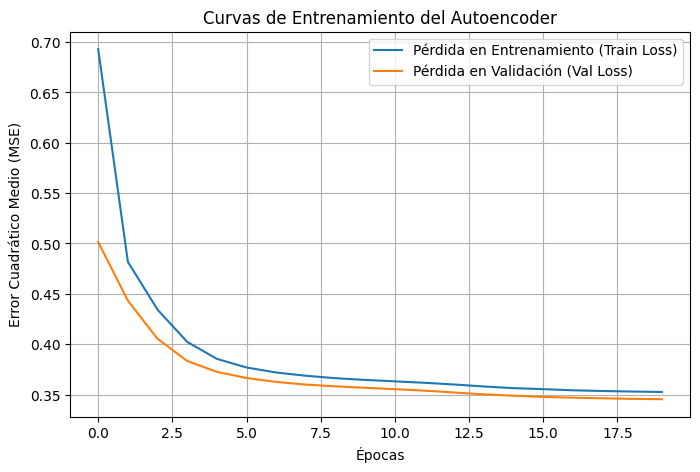

In [ ]:
print("Entrenando Autoencoder (esto tomará 1 o 2 minutos)...")

history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=20,
    batch_size=256,
    validation_split=0.1, # Toma 10% del train_normal para validar
    shuffle=True,
    verbose=1
)

# GRAFICAR CURVAS DE ENTRENAMIENTO (Requisito del TP)
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Pérdida en Entrenamiento (Train Loss)')
plt.plot(history.history['val_loss'], label='Pérdida en Validación (Val Loss)')
plt.title('Curvas de Entrenamiento del Autoencoder')
plt.xlabel('Épocas')
plt.ylabel('Error Cuadrático Medio (MSE)')
plt.legend()
plt.grid(True)
plt.show()

Celda 6: Evaluar Autoencoder y graficar comparativa final

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step
✅ AUC-PR Autoencoder: 0.5302


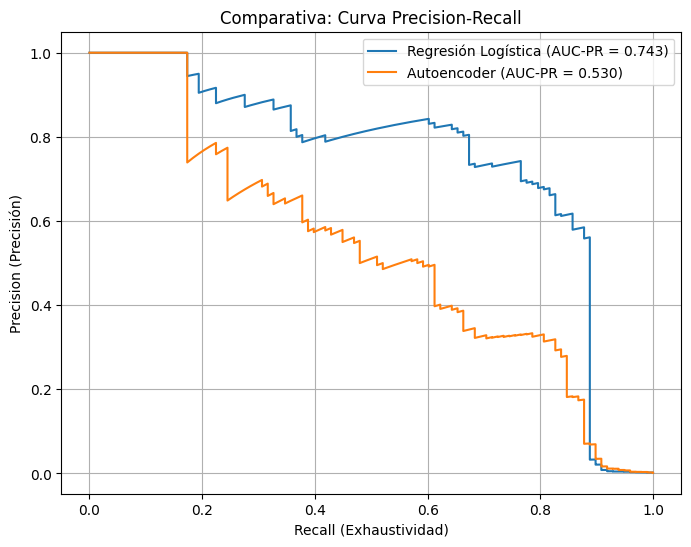

In [ ]:
# Inferencia: Pasamos TODOS los datos de prueba (normales y fraudes) por la red
X_test_pred = autoencoder.predict(X_test)

# El "puntaje de anomalía" es el Error Cuadrático Medio (MSE) de la reconstrucción
# Si la red no sabe reconstruirlo bien, el error es alto -> ¡ES FRAUDE!
mse = np.mean(np.power(X_test - X_test_pred, 2), axis=1)

# Calculamos el AUC-PR del Autoencoder
auc_pr_ae = average_precision_score(y_test, mse)
print(f"✅ AUC-PR Autoencoder: {auc_pr_ae:.4f}")

# GRAFICAR CURVAS PRECISION-RECALL (Requisito del TP)
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_pred_prob_lr)
precision_ae, recall_ae, _ = precision_recall_curve(y_test, mse)

plt.figure(figsize=(8, 6))
plt.plot(recall_lr, precision_lr, label=f'Regresión Logística (AUC-PR = {auc_pr_lr:.3f})')
plt.plot(recall_ae, precision_ae, label=f'Autoencoder (AUC-PR = {auc_pr_ae:.3f})')
plt.title('Comparativa: Curva Precision-Recall')
plt.xlabel('Recall (Exhaustividad)')
plt.ylabel('Precision (Precisión)')
plt.legend()
plt.grid(True)
plt.show()